## Лабораторная работа №1 | Вариант 4

### 1. Numpy

In [2]:
import numpy as np

1. Найти индексы не нулевых элементов массива [1,2,0,0,4,0]

In [3]:
arr = [1, 2, 0, 0, 4, 0]
np.flatnonzero(arr)

array([0, 1, 4])

2. Создайте единичную матрицу размером 3х3

In [3]:
np.eye(3, dtype=int)

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]])

3. Создайте матрицу-шахматную доску 8х8 используя функцию `tile`

In [4]:
tile = np.array([[0, 1], [1, 0]])
np.tile(tile, (4, 4))

array([[0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 1, 0, 1],
       [1, 0, 1, 0, 1, 0, 1, 0]])

4. Дан 1D массив, удалите все элементы которые входят в диапазон `[3, 8]` inplace

In [5]:
arr = np.array([0, 4, 4, 2, 1, 4, 8, 7, 10, 15])
remaining = arr[(arr < 3) | (arr > 8)]
# Меняем размер исходного массива и записываем в него оставшиеся элементы.
arr.resize(remaining.size, refcheck=False)
arr[:] = remaining
arr

array([ 0,  2,  1, 10, 15])

5. Создайте случайный вектор размером 10 элементов и замените максимальный элемент на 0

In [6]:
rng = np.random.default_rng(42)
vector = rng.random(10)
max_index = vector.argmax()
print(f"Максимум: {vector[max_index]:.4f}, индекс: {max_index}")
vector[max_index] = 0
vector

Максимум: 0.9756, индекс: 5


array([0.77395605, 0.43887844, 0.85859792, 0.69736803, 0.09417735,
       0.        , 0.7611397 , 0.78606431, 0.12811363, 0.45038594])

6. Как распечатать все значения в массиве?

In [7]:
arr = np.arange(30)
with np.printoptions(threshold=np.inf):
    print(arr)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]


7. Рассмотрим случайный вектор с формой 100х2, представляющей координаты, и найдем расстояния от точки к точке

In [8]:
points = np.random.default_rng(42).random((100, 2))
# Разность координат для каждой пары точек имеет форму (100, 100, 2).
differences = points[:, None, :] - points[None, :, :]
distances = np.linalg.norm(differences, axis=2)
distances

array([[0.        , 0.2719947 , 0.86613689, ..., 0.67277843, 0.46935703,
        0.59165638],
       [0.2719947 , 0.        , 0.81348895, ..., 0.87515404, 0.31399077,
        0.76698338],
       [0.86613689, 0.81348895, 0.        , ..., 0.79854455, 0.51521425,
        0.67311135],
       ...,
       [0.67277843, 0.87515404, 0.79854455, ..., 0.        , 0.82609759,
        0.13797631],
       [0.46935703, 0.31399077, 0.51521425, ..., 0.82609759, 0.        ,
        0.69334849],
       [0.59165638, 0.76698338, 0.67311135, ..., 0.13797631, 0.69334849,
        0.        ]], shape=(100, 100))

8. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [9]:
values = np.array([1.9, -2.8, 3.0], dtype=np.float32)
# Представление int32 использует тот же буфер. Записываем туда целые значения.
int_values = values.view(np.int32)
np.copyto(int_values, values, casting="unsafe")
int_values

array([ 1, -2,  3], dtype=int32)

9. Как прочитать заданный файл?
```
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
```

In [10]:
from io import StringIO

csv_text = """1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11"""
np.genfromtxt(StringIO(csv_text), delimiter=",", autostrip=True)

array([[ 1.,  2.,  3.,  4.,  5.],
       [ 6., nan, nan,  7.,  8.],
       [nan, nan,  9., 10., 11.]])

10. Какой эквивалент enumerate для numpy массивов?

In [11]:
matrix = np.array([[10, 20], [30, 40]])
for index, value in np.ndenumerate(matrix):
    print(index, value)

(0, 0) 10
(0, 1) 20
(1, 0) 30
(1, 1) 40


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Файл: `russian-housing-market.csv`

```
price_doc - Цена продажи
id - Id транзакции
timestamp - Дата транзакции
full_sq - суммарная площадь в квадратных метрах, включая лоджию, валконы и отдельные нежилые помещения
life_sq - жилая площаль в квадратных метрах, исключая лоджии, балконы и прочие нежилые помещения
floor - для апартаментов, этаж помещения
max_floor - количество этажей в здании
material - материал стен
build_year - год постройки
num_room - количество жилых комнат
kitch_sq - площадь кухни
state - состояние апартаментов
product_type - покупка или инвестиция собственника-арендатора
sub_area - название района
```

In [12]:
import pandas as pd
from IPython.display import display

In [13]:
housing = pd.read_csv("russian-housing-market.csv", parse_dates=["timestamp"])
housing.head()

,id,timestamp,full_sq,life_sq,floor,max_floor,material,build_year,num_room,kitch_sq,state,product_type,sub_area,price_doc
0,1,2011-08-20,43,27.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Bibirevo,5850000
1,2,2011-08-23,34,19.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Nagatinskij Zaton,6000000
2,3,2011-08-27,43,29.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Tekstil'shhiki,5700000
3,4,2011-09-01,89,50.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Mitino,13100000
4,5,2011-09-05,77,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Investment,Basmannoe,16331452


1. Посчитайте количество записей в датасете с отсутствующей информацией о жилой площади жилого помещения

In [14]:
missing_life_sq = housing["life_sq"].isna()
print(f"Записей без жилой площади: {missing_life_sq.sum()}")

Записей без жилой площади: 6383


2. Предложите способ заменить отсутствующие значения из пункта 1 и реализуйте его. Способ нужно аргументировать(сказать почему это достаточно хорошее приближение)

Для каждой группы квартир по полной площади берём медиану доли жилой площади в полной и умножаем её на полную площадь конкретной квартиры. Размер квартиры известен, а доля жилой площади может различаться у маленьких и больших квартир. Медиана устойчива к выбросам. Доли считаем по записям, где жилая площадь положительна и не превышает полную.

In [15]:
area_band = pd.cut(housing["full_sq"], bins=[0, 30, 45, 60, 80, 120, np.inf])
valid_life_sq = housing["life_sq"].gt(0) & housing["life_sq"].le(housing["full_sq"])
living_share = housing["life_sq"].where(valid_life_sq) / housing["full_sq"]
typical_share = living_share.groupby(area_band, observed=True).transform("median")
estimated_life_sq = housing["full_sq"] * typical_share.fillna(living_share.median())
housing["life_sq"] = housing["life_sq"].fillna(estimated_life_sq.round(1))

print(f"Заполнено пропусков: {missing_life_sq.sum() - housing['life_sq'].isna().sum()}")
print(f"Осталось пропусков: {housing['life_sq'].isna().sum()}")

Заполнено пропусков: 6383
Осталось пропусков: 0


3. Какие значения имеет 25, 50 и 75 перцентили полной площади помещения

In [16]:
percentiles = housing["full_sq"].quantile([0.25, 0.50, 0.75])
percentiles.index = ["25-й", "50-й", "75-й"]
percentiles.rename("Полная площадь, м²")

25-й    38.0
50-й    49.0
75-й    63.0
Name: Полная площадь, м², dtype: float64

4. Посчитайте среднюю стоимость продажи помещений с общей площадью от 50 до 70 квадратных метров

In [17]:
area_50_to_70 = housing["full_sq"].between(50, 70, inclusive="both")
mean_price_50_to_70 = housing.loc[area_50_to_70, "price_doc"].mean()
print(f"Средняя цена при площади 50–70 м²: {mean_price_50_to_70:,.2f} ₽")

Средняя цена при площади 50–70 м²: 7,243,041.19 ₽


5. Какая максимальная этажность здания представлена в датасете

In [18]:
max_floors = housing["max_floor"].max()
print(f"Максимальное значение max_floor в датасете: {max_floors:.0f} этажей")

Максимальное значение max_floor в датасете: 117 этажей


6. Выявите район с самым дорогим жильем

In [19]:
mean_price_by_area = housing.groupby("sub_area")["price_doc"].mean()
most_expensive_area = mean_price_by_area.idxmax()
mean_price = mean_price_by_area.loc[most_expensive_area]
print(f"Самая высокая средняя цена: {most_expensive_area}, {mean_price:,.2f} ₽")

most_expensive_sale = housing.loc[housing["price_doc"].idxmax()]
print(
    f"Самая дорогая отдельная сделка: {most_expensive_sale['sub_area']}, "
    f"{most_expensive_sale['price_doc']:,.0f} ₽"
)

Самая высокая средняя цена: Hamovniki, 20,116,565.54 ₽
Самая дорогая отдельная сделка: Teplyj Stan, 111,111,112 ₽


7. Посчитайте среднюю стоимость за квадратный метр жилья в Митино(Mitino)

In [20]:
mitino = housing.loc[housing["sub_area"].eq("Mitino") & housing["full_sq"].gt(0)]
mitino_price_per_sqm = mitino["price_doc"] / mitino["full_sq"]
print(f"Средняя цена квадратного метра в Митино: {mitino_price_per_sqm.mean():,.2f} ₽/м²")

Средняя цена квадратного метра в Митино: 171,841.40 ₽/м²


8. Посчитайте среднюю площадь комнаты в Бибирево

In [21]:
bibirevo = housing.loc[
    housing["sub_area"].eq("Bibirevo")
    & housing["num_room"].gt(0)
    & housing["life_sq"].gt(0)
    & housing["life_sq"].le(housing["full_sq"])
]
# Сначала считаем среднюю площадь комнаты в каждой квартире.
room_area = bibirevo["life_sq"] / bibirevo["num_room"]
print(f"Средняя площадь комнаты в Бибирево: {room_area.mean():.2f} м²")

Средняя площадь комнаты в Бибирево: 16.06 м²


9. Проанализируйте есть ли разница в цене между квартирами на 1 и 9 этажах

В выборке средняя полная цена квартиры на 9-м этаже на 20,9% выше, чем на 1-м, а медианная выше примерно на 830 тыс. ₽. Таблица также показывает медианную площадь и цену за м². Состав сделок по районам, датам и другим характеристикам может различаться, поэтому сравнение описательное.

In [22]:
floor_sales = housing.loc[housing["floor"].isin([1, 9])].copy()
floor_sales["price_per_sqm"] = (
    floor_sales["price_doc"] / floor_sales["full_sq"].where(floor_sales["full_sq"].gt(0))
)
floor_summary = floor_sales.groupby("floor").agg(
    **{
        "Количество сделок": ("price_doc", "size"),
        "Средняя цена, ₽": ("price_doc", "mean"),
        "Медианная цена, ₽": ("price_doc", "median"),
        "Медианная площадь, м²": ("full_sq", "median"),
        "Медианная цена за м², ₽": ("price_per_sqm", "median"),
    }
)
floor_summary.index = floor_summary.index.astype(int).rename("Этаж")
display(floor_summary.round(2))

mean_prices = floor_summary["Средняя цена, ₽"]
difference_pct = (mean_prices.loc[9] / mean_prices.loc[1] - 1) * 100
print(f"Разница средней цены (9-й этаж относительно 1-го): {difference_pct:+.1f}%")

,Количество сделок,"Средняя цена, ₽","Медианная цена, ₽","Медианная площадь, м²","Медианная цена за м², ₽"
Этаж,,,,,
1,2002,5739379.59,5569575.0,44.0,134494.95
9,1843,6937582.58,6400000.0,48.0,138513.51


Разница средней цены (9-й этаж относительно 1-го): +20.9%


10. Найдите минимальную стоимость квартиры с жилой площадью не менее 60 квадратных метров, не менее чем 3мя комнатами и не ниже чем на 5 этаже

In [23]:
qualifying_sales = housing.loc[
    housing["life_sq"].ge(60) & housing["num_room"].ge(3) & housing["floor"].ge(5)
]
cheapest_sale = qualifying_sales.loc[qualifying_sales["price_doc"].idxmin()]
print(f"Минимальная цена: {cheapest_sale['price_doc']:,.0f} ₽")
display(cheapest_sale[["id", "sub_area", "life_sq", "num_room", "floor"]].to_frame("Значение"))

Минимальная цена: 1,000,000 ₽


,Значение
id,11744
sub_area,Mitino
life_sq,65.0
num_room,4.0
floor,17.0


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Как менялась средняя цена квартиры в Нагатинском Затоне(Nagatinski Zaton) с течением времени

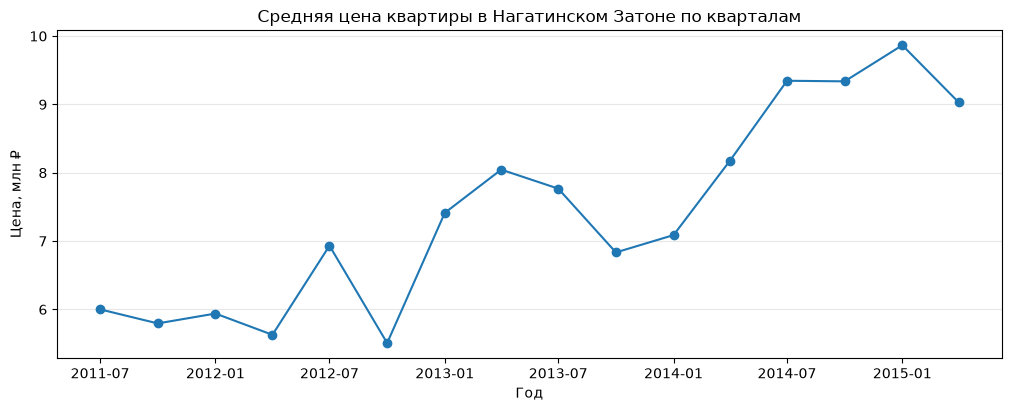

In [24]:
import matplotlib.pyplot as plt

nagatino = housing.loc[housing["sub_area"].eq("Nagatinskij Zaton")]
quarterly_mean = nagatino.resample("QS", on="timestamp")["price_doc"].mean() / 1_000_000

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(quarterly_mean.index, quarterly_mean, marker="o", color="tab:blue")
ax.set(
    title="Средняя цена квартиры в Нагатинском Затоне по кварталам",
    xlabel="Год",
    ylabel="Цена, млн ₽",
)
ax.grid(axis="y", alpha=0.3)
plt.show()

2. Постройте гистограмму распределения цен на квартиры с общей площадью более 50 кв.метров

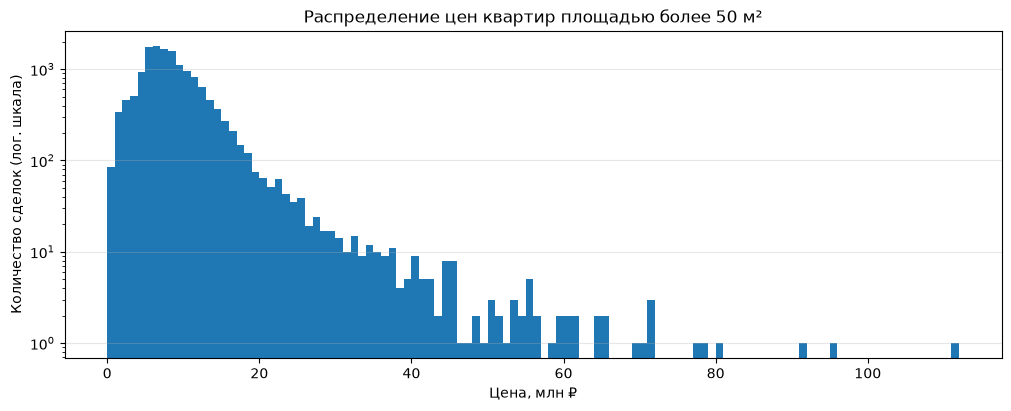

In [25]:
large_apartment_prices = housing.loc[housing["full_sq"].gt(50), "price_doc"] / 1_000_000
bins = np.arange(0, np.ceil(large_apartment_prices.max()) + 1, 1)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.hist(large_apartment_prices, bins=bins, log=True, color="tab:blue")
ax.set(
    title="Распределение цен квартир площадью более 50 м²",
    xlabel="Цена, млн ₽",
    ylabel="Количество сделок (лог. шкала)",
)
ax.grid(axis="y", alpha=0.3)
plt.show()

3. Визуализируйте количество проданных квартир в разных районах

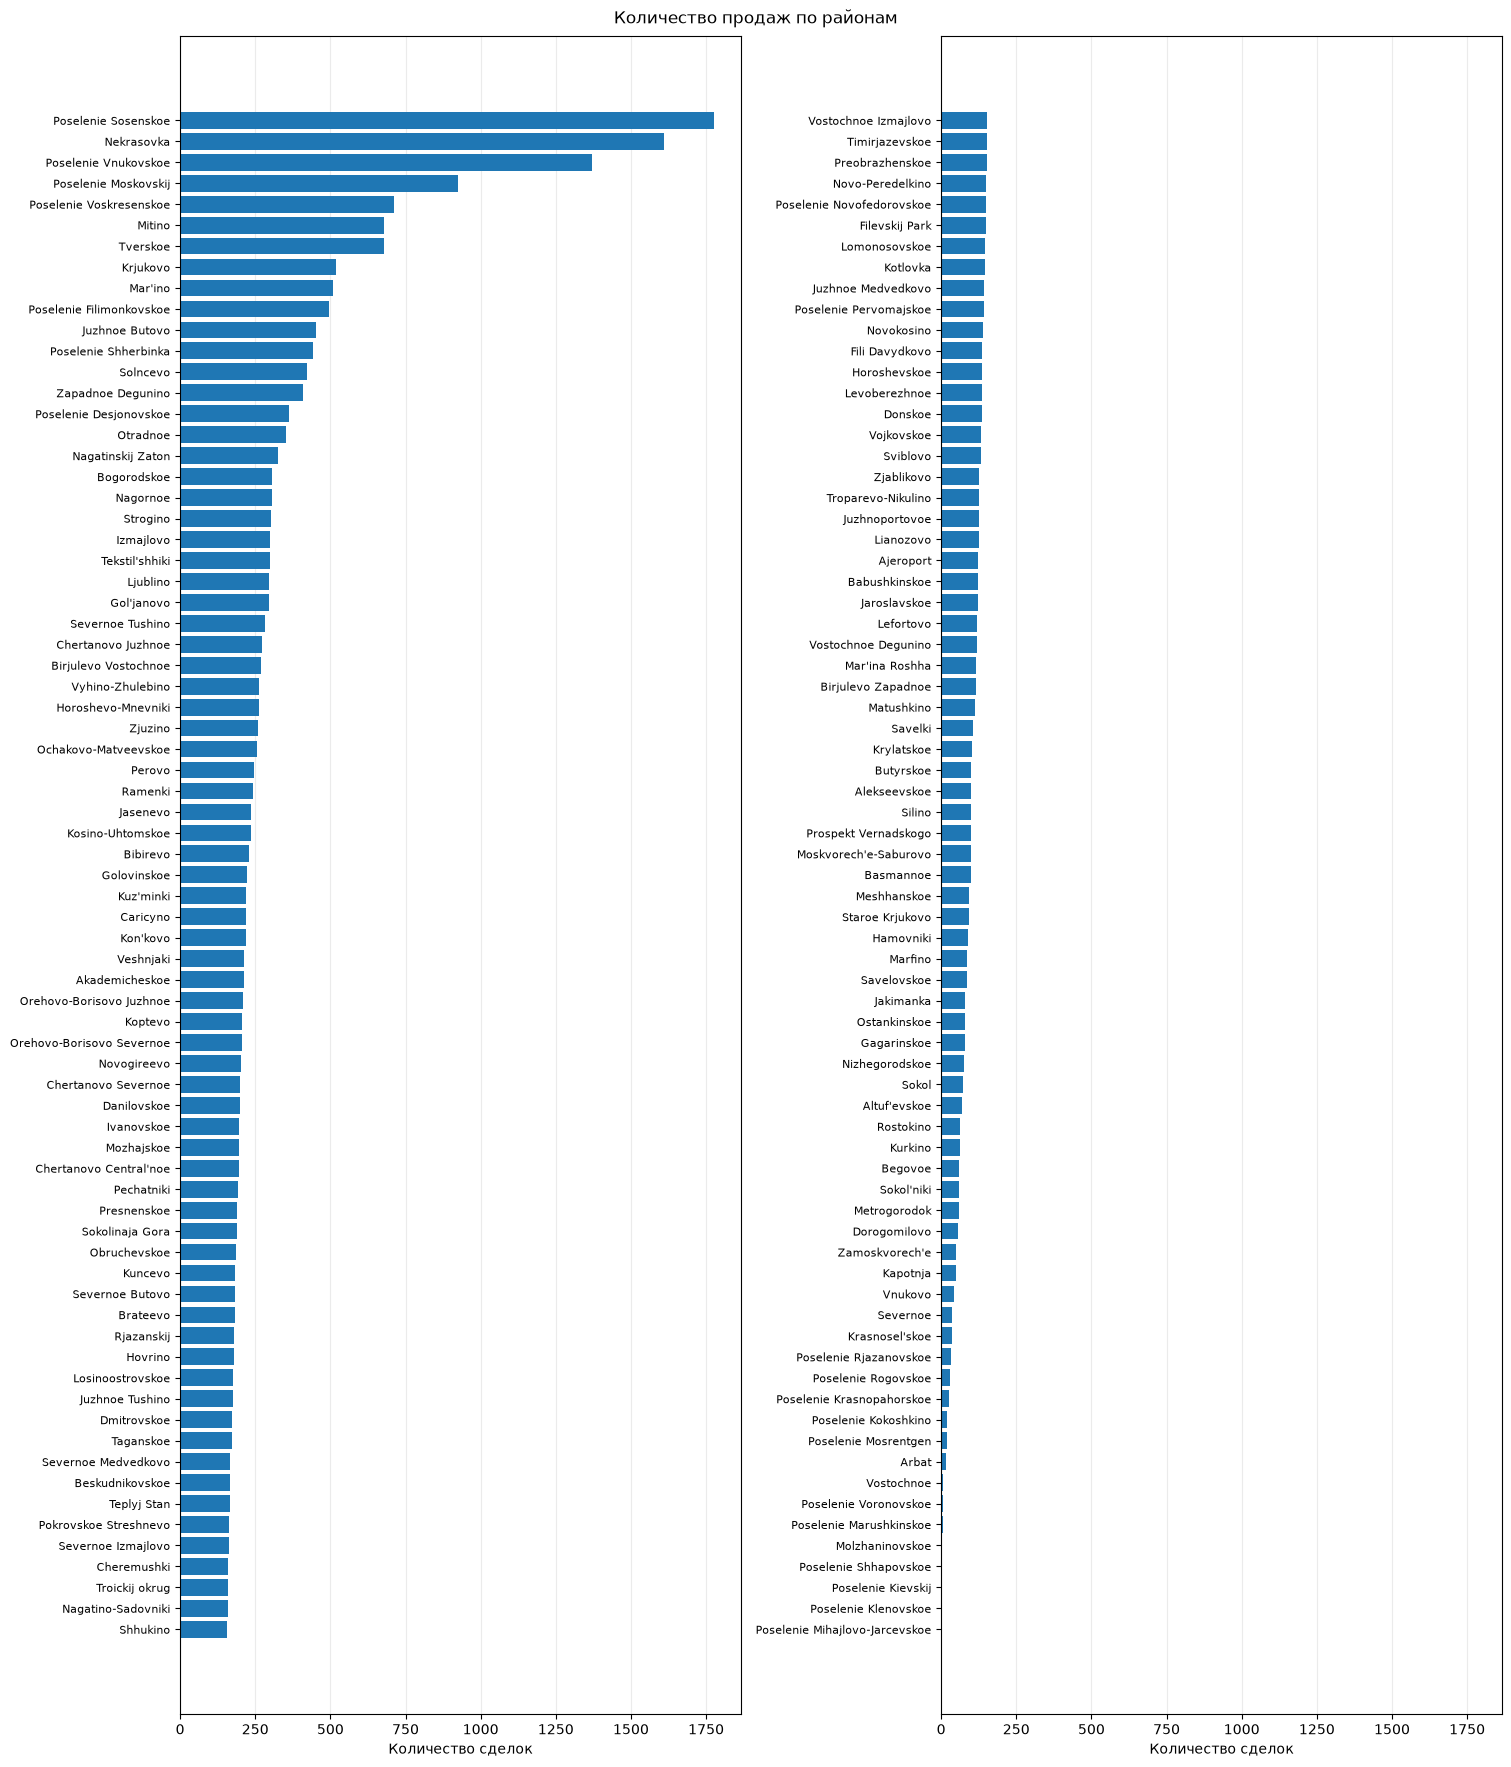

In [26]:
def plot_districts(values, title, x_label, color):
    ranked = values.sort_values(ascending=False)
    split = (len(ranked) + 1) // 2
    fig, axes = plt.subplots(
        1, 2, figsize=(15, 0.22 * split + 1.5), sharex=True, layout="constrained"
    )
    for ax, districts in zip(axes, (ranked.iloc[:split], ranked.iloc[split:])):
        ax.barh(districts.index, districts, color=color)
        ax.invert_yaxis()
        ax.set_xlabel(x_label)
        ax.tick_params(axis="y", labelsize=8)
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.25)
    fig.suptitle(title)
    plt.show()


sales_by_area = housing.groupby("sub_area").size()
plot_districts(sales_by_area, "Количество продаж по районам", "Количество сделок", "tab:blue")

4. Постройте box plot отображающий распределение полных площадей квартир в Басманном районе

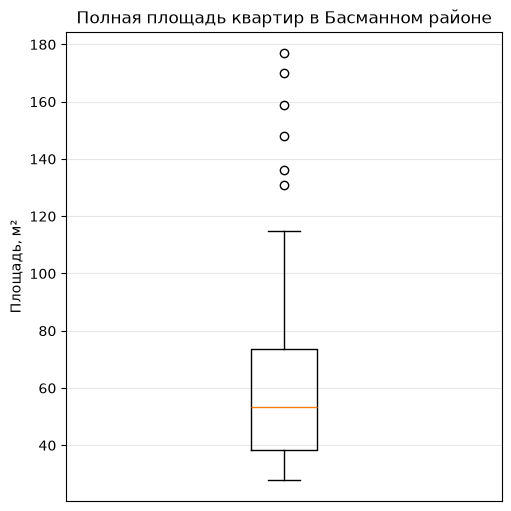

In [27]:
basmannoe_area = housing.loc[housing["sub_area"].eq("Basmannoe"), "full_sq"]

fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")
ax.boxplot(basmannoe_area)
ax.set(title="Полная площадь квартир в Басманном районе", ylabel="Площадь, м²")
ax.set_xticks([])
ax.grid(axis="y", alpha=0.3)
plt.show()

5. Визуализируйте зависимость средней стоимости квартир в зависимости от этажа

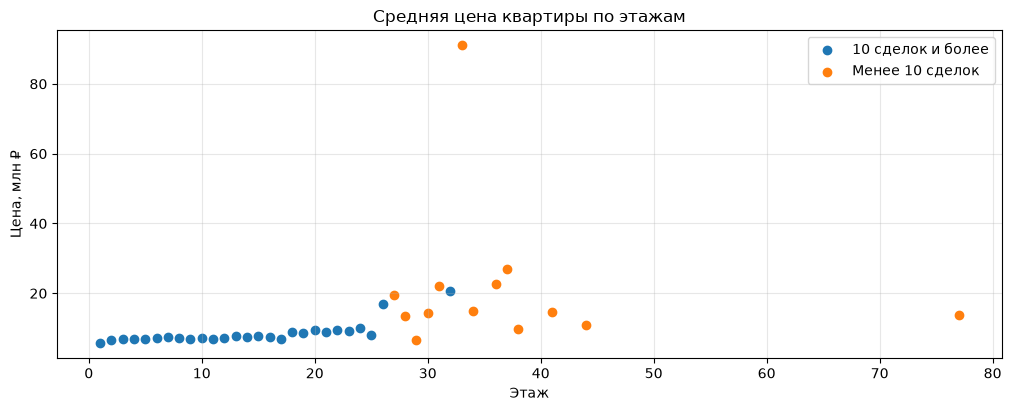

In [28]:
prices_by_floor = (
    housing.loc[housing["floor"].gt(0)]
    .groupby("floor")["price_doc"]
    .agg(mean_price="mean", sales="size")
)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
enough_sales = prices_by_floor["sales"].ge(10)
for mask, label, color in [
    (enough_sales, "10 сделок и более", "tab:blue"),
    (~enough_sales, "Менее 10 сделок", "tab:orange"),
]:
    group = prices_by_floor.loc[mask]
    ax.scatter(group.index, group["mean_price"] / 1_000_000, label=label, color=color)

ax.set(title="Средняя цена квартиры по этажам", xlabel="Этаж", ylabel="Цена, млн ₽")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

6. Покажите как меняется средняя площадь квартир в зависимости от района

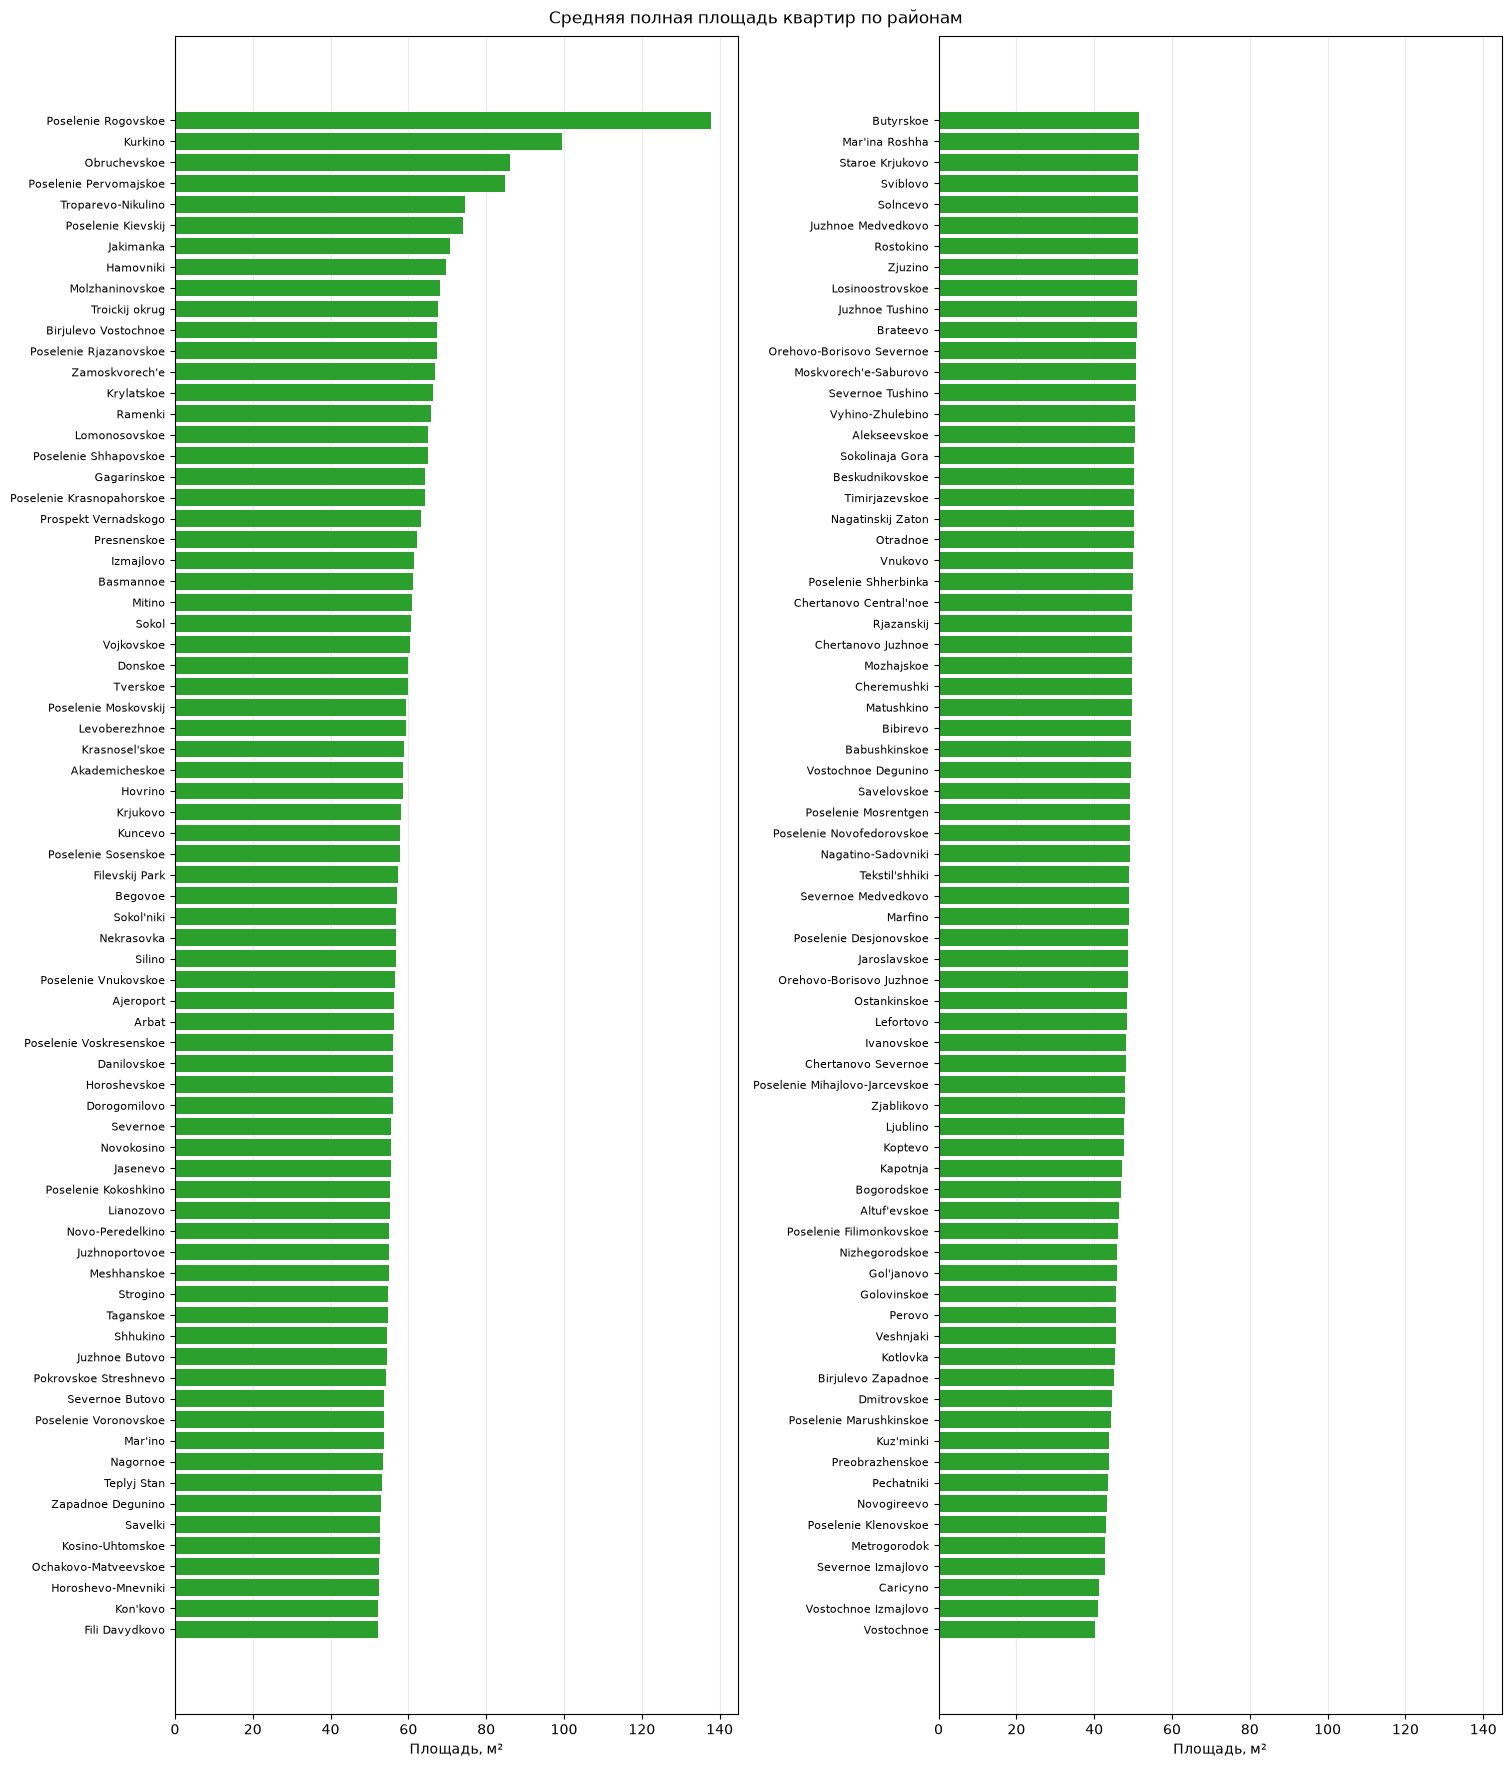

In [29]:
mean_area_by_district = housing.groupby("sub_area")["full_sq"].mean()
plot_districts(
    mean_area_by_district, "Средняя полная площадь квартир по районам", "Площадь, м²", "tab:green"
)

7. Постройте график изменения медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014 года*

\* Задание на доп. балл

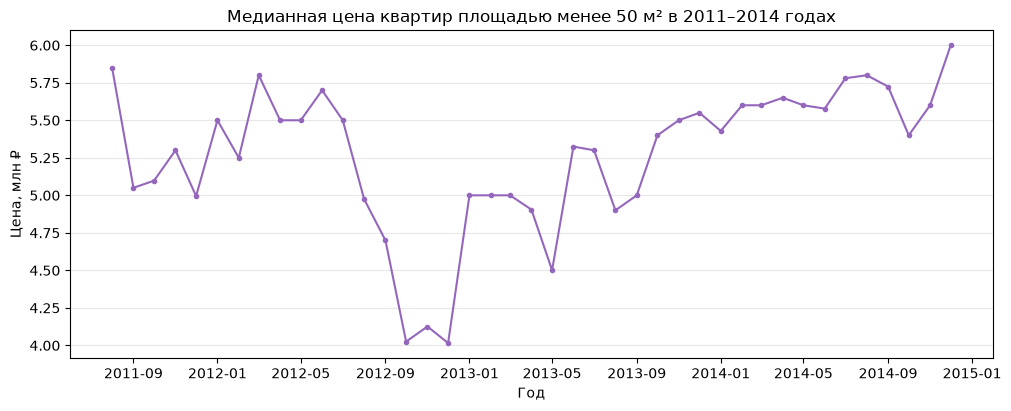

In [30]:
small_apartments = housing.loc[
    housing["full_sq"].gt(0)
    & housing["full_sq"].lt(50)
    & housing["timestamp"].ge("2011-01-01")
    & housing["timestamp"].lt("2015-01-01")
]
monthly_median = small_apartments.resample("MS", on="timestamp")["price_doc"].median()
monthly_median = monthly_median.reindex(pd.date_range("2011-01-01", "2014-12-01", freq="MS"))

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(monthly_median.index, monthly_median / 1_000_000, marker=".", color="tab:purple")
ax.set(
    title="Медианная цена квартир площадью менее 50 м² в 2011–2014 годах",
    xlabel="Год",
    ylabel="Цена, млн ₽",
)
ax.grid(axis="y", alpha=0.3)
plt.show()